# Chapter 13: Learning to Predict

## Learning Objectives

This chapter demonstrates how a model can learn a relationship between input features and numerical targets.

The objectives are:
1. Prepare input and target tensors.
2. Build a simple neural network in PyTorch.
3. Define a loss function and optimizer.
4. Train the model to predict numerical values.
5. Evaluate predictions using mean squared error.

## 1. Predicting Numerical Values

Regression is a supervised learning task in which a model predicts a numerical target.

For example, a model may learn to predict an output from an input using training examples.

During training, the model produces predictions, compares them with the target values, and updates its parameters to reduce the loss.

Mean Squared Error (MSE) is one common regression loss function:

MSE = mean((prediction - target)²)

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)

# Create a simple dataset: y = 2x + 1
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y = 2 * X + 1

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five input values:")
print(X[:5])

print("\nFirst five target values:")
print(y[:5])

Input shape: torch.Size([100, 1])
Target shape: torch.Size([100, 1])

First five input values:
tensor([[-2.0000],
        [-1.9596],
        [-1.9192],
        [-1.8788],
        [-1.8384]])

First five target values:
tensor([[-3.0000],
        [-2.9192],
        [-2.8384],
        [-2.7576],
        [-2.6768]])


In [2]:
# Define a simple linear regression model
model = nn.Linear(
    in_features=1,
    out_features=1
)

print(model)
print("\nInitial weight:", model.weight.data)
print("Initial bias:", model.bias.data)

Linear(in_features=1, out_features=1, bias=True)

Initial weight: tensor([[0.7645]])
Initial bias: tensor([0.8300])


In [3]:
# Mean Squared Error loss
loss_function = nn.MSELoss()

# Stochastic Gradient Descent optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

print("Loss function:", loss_function)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [4]:
epochs = 500
loss_history = []

for epoch in range(epochs):
    # Forward pass
    predictions = model(X)

    # Calculate loss
    loss = loss_function(predictions, y)

    # Clear old gradients
    optimizer.zero_grad()

    # Calculate gradients
    loss.backward()

    # Update parameters
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss.item():.6f}"
        )

Epoch 100/500, Loss: 0.009349
Epoch 200/500, Loss: 0.000045
Epoch 300/500, Loss: 0.000000
Epoch 400/500, Loss: 0.000000
Epoch 500/500, Loss: 0.000000


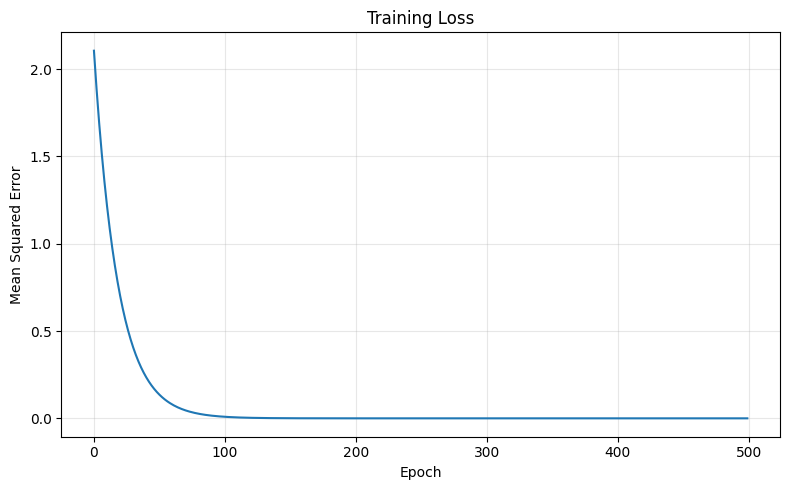

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Learned weight: 1.999997854232788
Learned bias: 0.9999930262565613
Final MSE: 5.516842191410909e-11


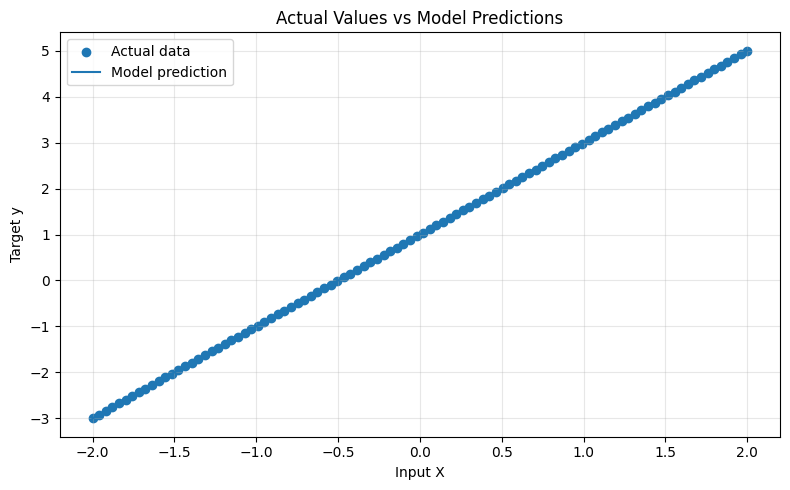

In [6]:
model.eval()

with torch.no_grad():
    predictions = model(X)

print("Learned weight:", model.weight.item())
print("Learned bias:", model.bias.item())
print("Final MSE:", loss_function(predictions, y).item())

plt.figure(figsize=(8, 5))
plt.scatter(X.numpy(), y.numpy(), label="Actual data")
plt.plot(X.numpy(), predictions.numpy(), label="Model prediction")
plt.title("Actual Values vs Model Predictions")
plt.xlabel("Input X")
plt.ylabel("Target y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion

A regression model learns to predict numerical targets by minimizing a loss function.

PyTorch simplifies training through its model layers, loss functions, automatic differentiation, and optimizers.

In this example, the model learns an approximately linear relationship between x and y. The experiment uses a simple synthetic dataset to demonstrate the training process.